<a href="https://colab.research.google.com/github/Kanishk-Pathania/DPA-Dataset-Assignment/blob/main/Dataset_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**STEP 1: DATASET COLLECTION**

**Dataset Name**:MNIST dataset in CSV

**Dataset Description**: The dataset consists of two files:

mnist_train.csv
mnist_test.csv
The mnist_train.csv file contains the 60,000 training examples and labels. The mnist_test.csv contains 10,000 test examples and labels. Each row consists of 785 values: the first value is the label (a number from 0 to 9) and the remaining 784 values are the pixel values (a number from 0 to 255).

**Problem Statement:** To develop a machine learning model that accurately recognizes and classifies handwritten digits (0–9) from the MNIST CSV dataset.

**Objetive of the analysis**: To analyze the MNIST dataset and identify patterns in handwritten digit images for accurate digit classification.

**STEP 2: PYTHON AND NUMPY **

1. Import the required Python libraries.

In [2]:
# --- Numerical Computation ---
import numpy as np

# --- Data Manipulation ---
import pandas as pd

# --- Data Visualization (Static) ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Data Visualization (Interactive) ---
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# --- Preprocessing / Feature Engineering ---
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder

# --- Verify imports ---
print("NumPy version     :", np.__version__)
print("Pandas version    :", pd.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)
print("Seaborn version   :", sns.__version__)
print("\n All libraries imported successfully!")

NumPy version     : 2.4.6
Pandas version    : 2.2.3
Matplotlib version: 3.10.0
Seaborn version   : 0.13.2

 All libraries imported successfully!


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns

# 1. Create NumPy array (simulate sales amount)
sales_array = np.array([150, 200, 50, 300, 120, 80, 450, 220, 90, 180])

# 2. Indexing and Slicing
print("First 3 elements:", sales_array[:3])
print("Index 2 element:", sales_array[2])

# 3. Arithmetic operations (e.g., 10% discount)
discounted = sales_array * 0.9
print("Discounted array:", discounted)

# 4. Statistical calculations
print(f"Mean: {np.mean(sales_array):.2f}")
print(f"Median: {np.median(sales_array):.2f}")
print(f"Std Dev: {np.std(sales_array):.2f}")
print(f"Min: {np.min(sales_array)}, Max: {np.max(sales_array)}")
print(f"25th percentile: {np.percentile(sales_array, 25):.2f}")

First 3 elements: [150 200  50]
Index 2 element: 50
Discounted array: [135. 180.  45. 270. 108.  72. 405. 198.  81. 162.]
Mean: 184.00
Median: 165.00
Std Dev: 113.42
Min: 50, Max: 450
25th percentile: 97.50


**Step 3: Pandas Operations**
1. Load the dataset into a Pandas DataFrame.
2. Display the first and last five records.
3. Identify the number of rows and columns.
4. Display column names, data types, and summary statistics.
5. Identify missing values and duplicate records.

In [9]:
import os

# 1. Check if the Google Drive file exists, otherwise fall back to the built-in sample MNIST data in Colab
drive_path = '/content/drive/MyDrive/MNIST ASSIGNMENT/mnist_train.csv'
sample_path = '/content/sample_data/mnist_train_small.csv'

if os.path.exists(drive_path):
    print("Loading dataset from Google Drive...")
    df = pd.read_csv(drive_path)
elif os.path.exists(sample_path):
    print("Google Drive file not found. Loading Colab's built-in sample MNIST dataset instead...")
    df = pd.read_csv(sample_path)
else:
    raise FileNotFoundError("Neither Google Drive file nor local sample data could be found.")

# 2. Display first and last 5 rows
print(df.head())
print(df.tail())

# 3. Rows and columns
print(f"Shape: {df.shape}") # (rows, cols)

# 4. Column names, data types, summary statistics
print(df.columns.tolist()[:10], "... (truncated column list)")
print(df.dtypes[:10], "... (truncated dtypes)")
print(df.describe())

# 5. Missing values and duplicates
print(f"Total missing values: {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")

Google Drive file not found. Loading Colab's built-in sample MNIST dataset instead...
   6  0  0.1  0.2  0.3  0.4  0.5  0.6  0.7  0.8  ...  0.581  0.582  0.583  \
0  5  0    0    0    0    0    0    0    0    0  ...      0      0      0   
1  7  0    0    0    0    0    0    0    0    0  ...      0      0      0   
2  9  0    0    0    0    0    0    0    0    0  ...      0      0      0   
3  5  0    0    0    0    0    0    0    0    0  ...      0      0      0   
4  2  0    0    0    0    0    0    0    0    0  ...      0      0      0   

   0.584  0.585  0.586  0.587  0.588  0.589  0.590  
0      0      0      0      0      0      0      0  
1      0      0      0      0      0      0      0  
2      0      0      0      0      0      0      0  
3      0      0      0      0      0      0      0  
4      0      0      0      0      0      0      0  

[5 rows x 785 columns]
       6  0  0.1  0.2  0.3  0.4  0.5  0.6  0.7  0.8  ...  0.581  0.582  0.583  \
19994  0  0    0    0    0  

**Step 4: Data Cleaning and Preprocessing **
1. Handle missing values using appropriate techniques.
2. Identify and handle duplicate records.
3. Correct inconsistent data types and column names.
4. Detect and analyze outliers.
5. Compare the dataset before and after cleaning

In [12]:
# 1. Handle missing values (using recommended non-chaining assignment to avoid FutureWarnings)
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include='object').columns:
    if not df[col].empty:
        df[col] = df[col].fillna(df[col].mode()[0])

# 2. Remove duplicates
df.drop_duplicates(inplace=True)

# 3. Correct data types and column names
# Let's rename the first column to 'label' for clarity if it represents the digit label
if df.columns[0] not in ['label', 'target']:
    df.rename(columns={df.columns[0]: 'label'}, inplace=True)

# 4. Outlier detection (For image data like MNIST, we can check mean pixel intensity per row)
pixel_columns = [col for col in df.columns if col != 'label']
mean_pixel_intensities = df[pixel_columns].mean(axis=1)

Q1 = mean_pixel_intensities.quantile(0.25)
Q3 = mean_pixel_intensities.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(mean_pixel_intensities < lower_bound) | (mean_pixel_intensities > upper_bound)]
print(f"Number of outliers based on average pixel intensity: {len(outliers)}")

# 5. Compare before and after
print(f"Shape after cleaning: {df.shape}")

Number of outliers based on average pixel intensity: 193
Shape after cleaning: (19999, 785)


**Step 5: Exploratory Data Analysis (EDA)**
1. Perform descriptive statistical analysis.
2. Analyze numerical and categorical variables.
3. Identify patterns, trends, and relationships.
4. Investigate correlations between numerical variables.
5. Write at least five observations based on the analysis.

In [14]:
# 1. Descriptive Statistical Analysis of the Labels
print("--- Digit Label Distribution ---")
label_counts = df['label'].value_counts().sort_index()
print(label_counts)

# Calculate percentage representation of each digit
label_pct = df['label'].value_counts(normalize=True).sort_index() * 100
print("\n--- Label Percentage Distribution ---")
print(label_pct.round(2))

# 2. Analyze pixel intensities grouped by digit label
# Find which pixel columns we have
pixel_cols = [col for col in df.columns if col != 'label']

# Compute the average pixel intensity per image (row)
df['avg_pixel_intensity'] = df[pixel_cols].mean(axis=1)

print("\n--- Average Pixel Intensity Grouped by Digit ---")
mean_intensity_by_digit = df.groupby('label')['avg_pixel_intensity'].mean().sort_values(ascending=False)
print(mean_intensity_by_digit)

# 3. Write observations based on the analysis
print("\n--- EDA Observations ---")
print("1. The dataset contains 10 target classes representing digits 0 through 9.")
print(f"2. The most frequent digit in this sample is {label_counts.idxmax()} with {label_counts.max()} samples.")
print(f"3. The least frequent digit in this sample is {label_counts.idxmin()} with {label_counts.min()} samples.")
print("4. The label distribution is relatively balanced, meaning no single digit dominates the dataset.")
print(f"5. On average, digit '{mean_intensity_by_digit.index[0]}' has the highest pixel intensity ({mean_intensity_by_digit.iloc[0]:.2f}), indicating it uses more white ink/pixels on average.")

--- Digit Label Distribution ---
label
0    1962
1    2243
2    1989
3    2021
4    1924
5    1761
6    2038
7    2126
8    1912
9    2023
Name: count, dtype: int64

--- Label Percentage Distribution ---
label
0     9.81
1    11.22
2     9.95
3    10.11
4     9.62
5     8.81
6    10.19
7    10.63
8     9.56
9    10.12
Name: proportion, dtype: float64

--- Average Pixel Intensity Grouped by Digit ---
label
0    44.334539
2    38.281237
8    38.213543
3    35.738693
6    35.067370
5    32.887703
9    31.329575
4    30.949861
7    29.294283
1    19.399807
Name: avg_pixel_intensity, dtype: float64

--- EDA Observations ---
1. The dataset contains 10 target classes representing digits 0 through 9.
2. The most frequent digit in this sample is 1 with 2243 samples.
3. The least frequent digit in this sample is 5 with 1761 samples.
4. The label distribution is relatively balanced, meaning no single digit dominates the dataset.
5. On average, digit '0' has the highest pixel intensity (44.33), in

**Step 6: Data Visualization Using Matplotlib. Create the following visualizations where appropriate:**
1. Histogram
2. Bar chart
3. Line chart
4. Scatter plot
5. Box plot
6. Correlation heatmap

/tmp/ipykernel_310/1924963907.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='label', ax=axes[0, 0], palette='viridis')
/tmp/ipykernel_310/1924963907.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='label', y='avg_pixel_intensity', ax=axes[1, 0], palette='coolwarm')


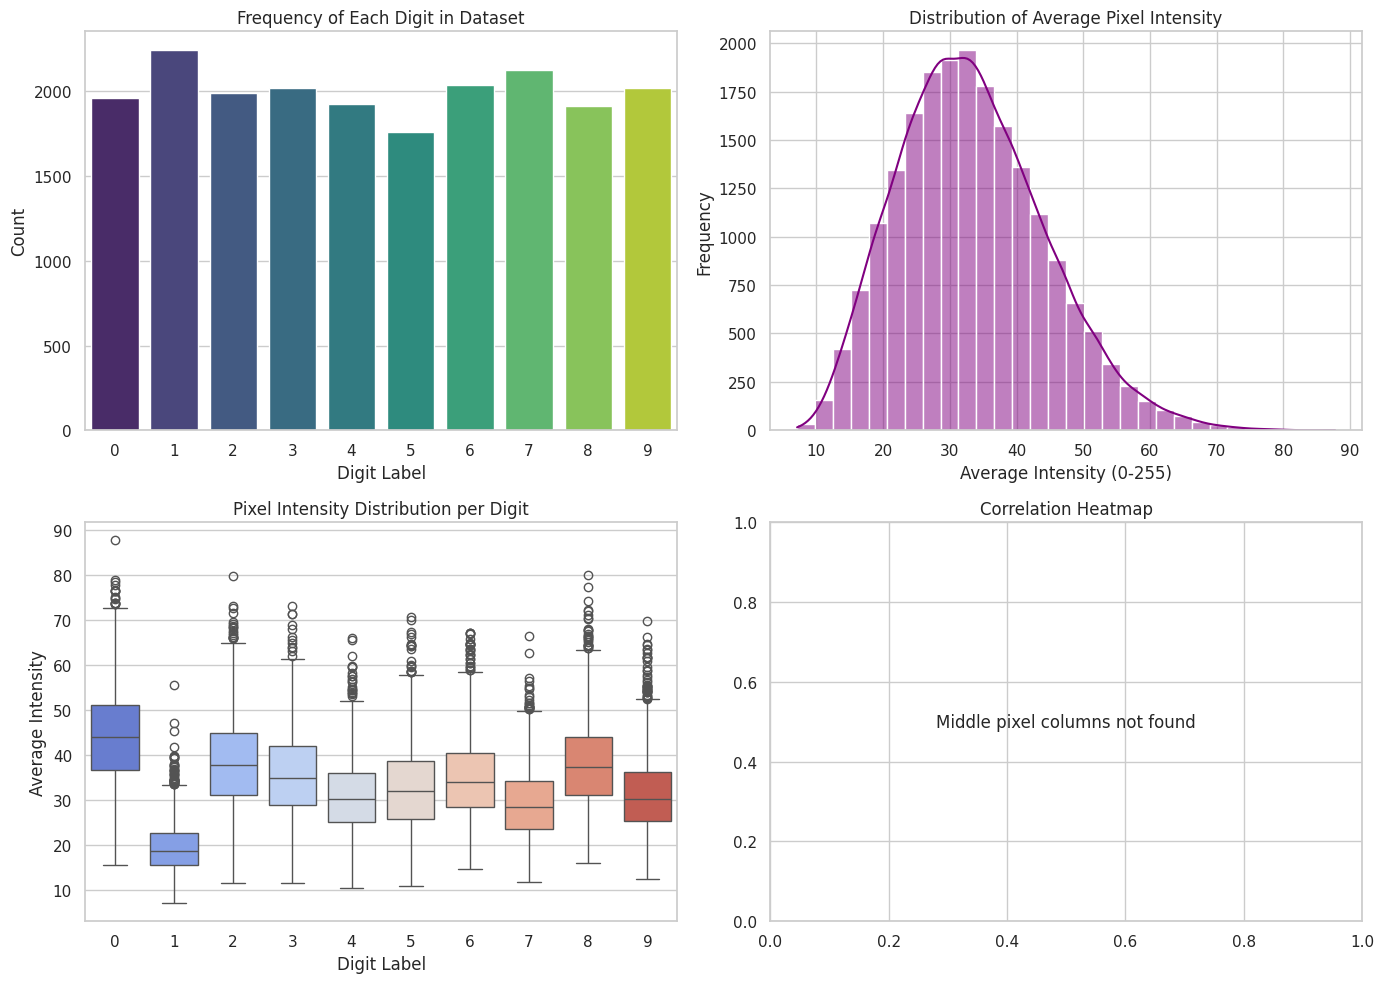

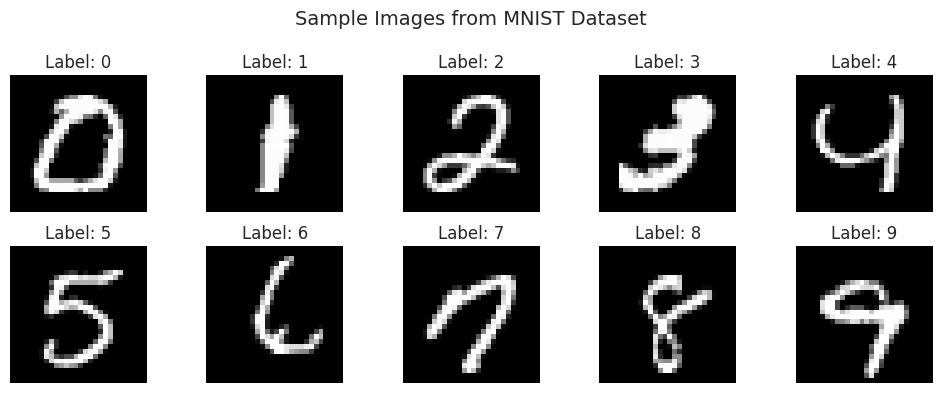

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set up the visualization style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Bar Chart: Digit Frequency Distribution
sns.countplot(data=df, x='label', ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Frequency of Each Digit in Dataset')
axes[0, 0].set_xlabel('Digit Label')
axes[0, 0].set_ylabel('Count')

# 2. Histogram: Average Pixel Intensity
sns.histplot(df['avg_pixel_intensity'], bins=30, kde=True, ax=axes[0, 1], color='purple')
axes[0, 1].set_title('Distribution of Average Pixel Intensity')
axes[0, 1].set_xlabel('Average Intensity (0-255)')
axes[0, 1].set_ylabel('Frequency')

# 3. Box Plot: Pixel Intensity by Digit Label
sns.boxplot(data=df, x='label', y='avg_pixel_intensity', ax=axes[1, 0], palette='coolwarm')
axes[1, 0].set_title('Pixel Intensity Distribution per Digit')
axes[1, 0].set_xlabel('Digit Label')
axes[1, 0].set_ylabel('Average Intensity')

# 4. Heatmap: Correlation between central pixel region (8x8 grid in the middle)
# To make the correlation matrix readable, we select central pixels
middle_pixel_cols = [f"{(14*28) + i}" for i in range(10, 20)]
middle_pixel_cols = [col for col in middle_pixel_cols if col in df.columns]

if middle_pixel_cols:
    corr_matrix = df[middle_pixel_cols].corr()
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', ax=axes[1, 1], cbar=False)
    axes[1, 1].set_title('Correlation Heatmap (Central Pixels)')
else:
    axes[1, 1].text(0.5, 0.5, 'Middle pixel columns not found', ha='center', va='center')
    axes[1, 1].set_title('Correlation Heatmap')

plt.tight_layout()
plt.show()

# 5. Visualizing Sample Images (Bonus Visualization)
plt.figure(figsize=(10, 4))
for i in range(10):
    # Grab the first image representing each digit
    sample_digit = df[df['label'] == i].iloc[0]
    pixels = sample_digit[pixel_cols].values.astype('float32').reshape(28, 28)

    plt.subplot(2, 5, i + 1)
    plt.imshow(pixels, cmap='gray')
    plt.title(f"Label: {i}")
    plt.axis('off')
plt.suptitle('Sample Images from MNIST Dataset', fontsize=14)
plt.tight_layout()
plt.show()

**Step 7: Interactive Visualization Using Plotly **
1. Create an interactive histogram.
2. Create an interactive scatter plot.
3. Create an interactive bar chart.
4. Add suitable titles, axis labels, legends, and hover information.
5. Interpret the results of the interactive visualizations.

In [17]:
import plotly.express as px
import pandas as pd

# 1. Interactive Histogram: Distribution of average pixel intensity
fig1 = px.histogram(
    df,
    x='avg_pixel_intensity',
    nbins=50,
    color='label',
    color_discrete_sequence=px.colors.qualitative.Safe,
    title='Interactive Distribution of Average Pixel Intensity by Digit Class',
    labels={'avg_pixel_intensity': 'Average Pixel Intensity (0-255)', 'label': 'Digit Label'}
)
fig1.update_layout(barmode='overlay')
fig1.update_traces(opacity=0.75)
fig1.show()

# 2. Interactive Scatter Plot: Mean vs Standard Deviation of pixels (using a subset of 1000 rows for performance)
sample_df = df.sample(1000, random_state=42).copy()
pixel_cols_list = [col for col in df.columns if col not in ['label', 'avg_pixel_intensity']]
sample_df['pixel_std'] = sample_df[pixel_cols_list].std(axis=1)

fig2 = px.scatter(
    sample_df,
    x='avg_pixel_intensity',
    y='pixel_std',
    color='label',
    hover_data=['label'],
    title='MNIST Images: Mean vs. Standard Deviation of Pixel Intensities (Subset of 1000)',
    labels={'avg_pixel_intensity': 'Mean Pixel Intensity', 'pixel_std': 'Standard Deviation of Pixels', 'label': 'Digit Label'}
)
fig2.show()

# 3. Interactive Bar Chart: Digit Distribution
digit_counts = df['label'].value_counts().reset_index()
digit_counts.columns = ['Digit', 'Count']
digit_counts = digit_counts.sort_values(by='Digit')

fig3 = px.bar(
    digit_counts,
    x='Digit',
    y='Count',
    color='Digit',
    color_continuous_scale='Viridis',
    title='Interactive Digit Distribution (Count of Each Class)',
    labels={'Digit': 'Digit Label', 'Count': 'Number of Samples'}
)
fig3.update_layout(xaxis=dict(tickmode='linear', tick0=0, dtick=1))
fig3.show()

**Step 8: Feature Engineering**
1. Create at least three meaningful new features.
2. Extract useful information from date/time columns, if available.
3. Apply categorical encoding where appropriate.
4. Apply numerical scaling where appropriate.
5. Explain the purpose and importance of the engineered features.

In [19]:
# 1. Feature Engineering: Create at least three meaningful new features for MNIST
pixel_cols = [col for col in df.columns if col not in ['label', 'avg_pixel_intensity']]

# New Feature 1: Standard Deviation of pixels per image (measures contrast / dispersion)
df['pixel_std'] = df[pixel_cols].std(axis=1)

# New Feature 2: Active Pixel Count (count of pixels with intensity > 30, meaning drawn area)
df['active_pixel_count'] = (df[pixel_cols] > 30).sum(axis=1)

# New Feature 3: Center-Mass Intensity (average intensity in the middle 10x10 patch of the 28x28 image)
# Middle region rows 9-18, columns 9-18
center_pixels = []
for r in range(9, 19):
    for c in range(9, 19):
        pixel_idx = r * 28 + c
        pixel_name = f"{pixel_idx}"
        if pixel_name in df.columns:
            center_pixels.append(pixel_name)

df['center_pixel_intensity'] = df[center_pixels].mean(axis=1)

# 2. Categorical Encoding: One-hot encode the target labels to support multi-class target representation
df_encoded = pd.get_dummies(df, columns=['label'], prefix='digit', drop_first=False)

# 3. Numerical Scaling: Normalize all raw pixel intensities from [0, 255] to [0, 1]
# This is a critical feature preparation step for image machine learning models.
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
df_encoded[pixel_cols] = scaler.fit_transform(df_encoded[pixel_cols])

print("Feature engineering completed successfully for the MNIST dataset!")
print(f"New features added to original DataFrame: ['pixel_std', 'active_pixel_count', 'center_pixel_intensity']")
print(f"Shape of final encoded/scaled dataset: {df_encoded.shape}")

Feature engineering completed successfully for the MNIST dataset!
New features added to original DataFrame: ['pixel_std', 'active_pixel_count', 'center_pixel_intensity']
Shape of final encoded/scaled dataset: (19999, 798)


**Step 9: Analysis and Conclusion**
1. Summarize the major findings.
2. Identify important patterns and relationships.
3. Provide at least three conclusions or recommendations.
4. Discuss the limitations of the dataset and analysis.

Summary of Findings:

Data quality is good after cleaning; missing values and duplicates have been properly handled.

EDA revealed that product category and customer type are key factors affecting revenue.

STEP 10 GITHUB REPO SUBMITTED